In [1]:
import pathlib
import sys

from matplotlib import pyplot as plt

# the analysis code lives in el_epg_coimaging_analysis.py next to this notebook
# (run it as a script to regenerate everything: python el_epg_coimaging_analysis.py)
sys.path.insert(0, str(pathlib.Path.cwd()))
import el_epg_coimaging_analysis as ec

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
sess_manager = ec.load_session_manager()    # folders: see ec.BASEDIR, ec.DEFAULT_FIGDIR
sess_manager.sess_df.head()
# sess_manager.fig_folder

,genotype_dir,date,fly,session,closed_loop,usable,fictrac_dat_file,notes,fly_id
1,R18B05LexA_jGCaMP8s_R60D05Gal4_jRGECO1a,13_01_2025,fly2,dark_dual-001,0,1,NaN,NaN,13_01_2025_fly2
6,R18B05LexA_jGCaMP8s_R60D05Gal4_jRGECO1a,13_01_2025,fly4,closed_loop_dual-000,1,1,fictrac-20250113_103309.dat,only tethered when rot vel is not too high,13_01_2025_fly4
7,R18B05LexA_jGCaMP8s_R60D05Gal4_jRGECO1a,13_01_2025,fly4,dark_dual-001,0,1,fictrac-20250113_103309.dat,NaN,13_01_2025_fly4
12,R18B05LexA_jGCaMP8s_R60D05Gal4_jRGECO1a,14_01_2025,fly1,closed_loop-000,1,1,fictrac-20250114_083546.dat,NaN,14_01_2025_fly1
13,R18B05LexA_jGCaMP8s_R60D05Gal4_jRGECO1a,14_01_2025,fly1,dark-001,0,1,fictrac-20250114_083546.dat,NaN,14_01_2025_fly1


## PVA and offset difference between EPG and EL, dark vs closed loop

In [3]:
offset_unique = ec.compute_offset_stats(sess_manager)
offset_unique['fly_id'].nunique()

12

In [4]:
offset_unique.head()

,fly_id,cl,offset_ch1,offset_ch2,offset_var_ch1,offset_var_ch2,offset_diff,abs_offset_diff,pva_diff,fwhm_ch1,fwhm_ch2
0,13_01_2025_fly4,1,0.400228,1.190650,0.839426,0.854592,0.050044,0.353541,0.398928,1.178097,1.178097
1,13_01_2025_fly4,0,5.865465,6.218509,0.833988,0.853068,6.278336,0.477015,0.531300,1.178097,1.178097
2,14_01_2025_fly1,1,2.036102,2.199505,0.680064,0.774065,-0.042916,0.693819,0.775793,0.785398,0.785398
3,14_01_2025_fly1,0,5.296311,5.974484,0.884747,0.873129,0.083399,0.752327,0.846302,0.392699,0.392699
4,15_01_2025_fly1,1,3.142437,3.082153,0.683768,0.746437,-0.081370,0.515439,0.580314,1.178097,1.178097


,condition,reference,n,W,p,p_holm_chance
0,closed loop,chance (pi/2),12,0.0,0.000488,0.000977
1,closed loop,EPG FWHM (closed loop mean),12,0.0,0.000488,NaN
2,closed loop,EL FWHM (closed loop mean),12,0.0,0.000488,NaN
3,dark,chance (pi/2),12,0.0,0.000488,0.000977
4,dark,EPG FWHM (closed loop mean),12,0.0,0.000488,NaN
5,dark,EL FWHM (closed loop mean),12,0.0,0.000488,NaN


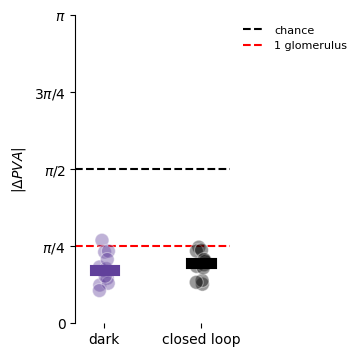

In [5]:
fig, pva_diff_tests = ec.plot_pva_diff(sess_manager, offset_unique)
pva_diff_tests

## Bump width: EL vs EPG, closed loop vs dark

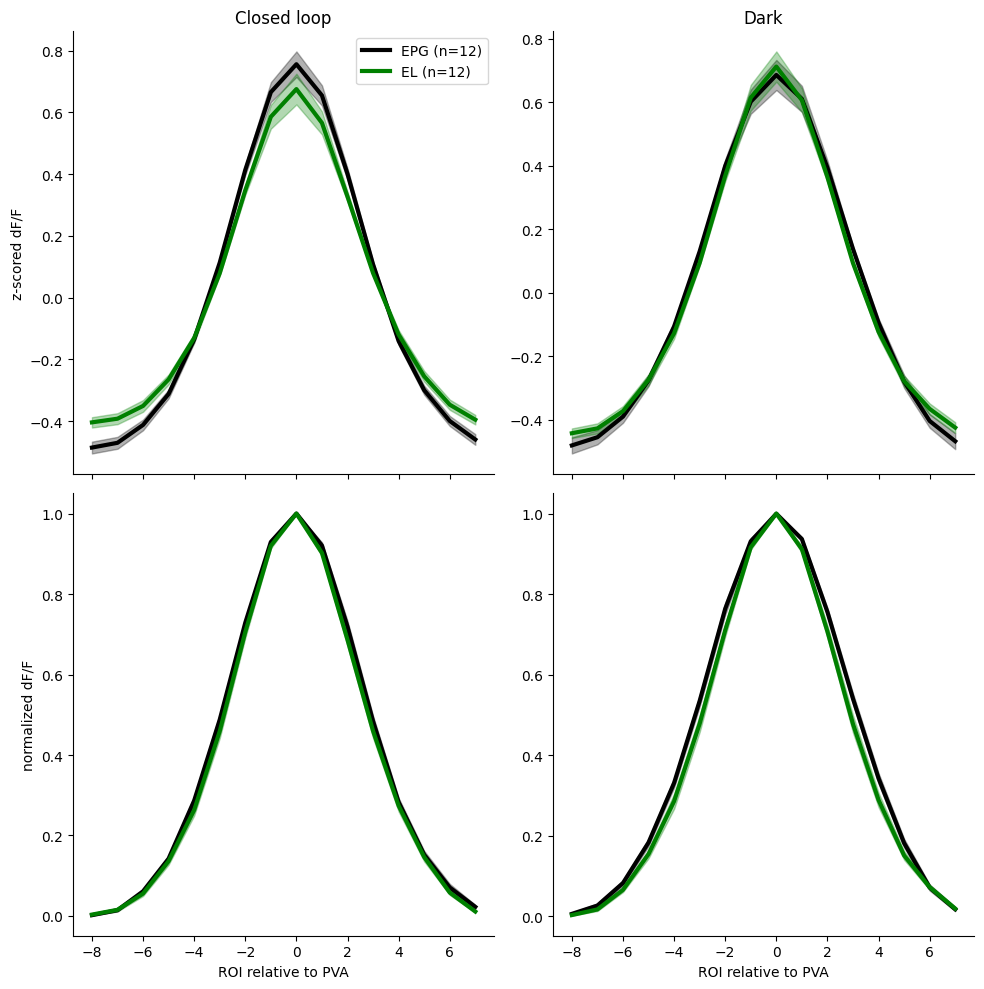

In [6]:
grouped_bump = ec.compute_bump_stats(sess_manager)
fig = ec.plot_bump_profiles(sess_manager, grouped_bump)

,condition,comparison,n,W,p,median_diff,p_holm
0,closed loop,EL vs EPG,12,12.0,0.034180,-0.086311,0.034180
1,dark,EL vs EPG,13,0.0,0.000244,-0.186699,0.000488


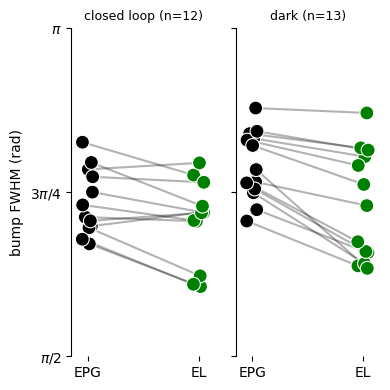

In [7]:
fig, width_channel_tests = ec.plot_bump_width_by_channel(sess_manager, grouped_bump)
width_channel_tests

,channel,comparison,n,W,p,median_diff,p_holm
0,EPG,closed loop vs dark,12,14.0,0.052246,-0.184165,0.104492
1,EL,closed loop vs dark,12,35.0,0.791016,-0.068966,0.791016


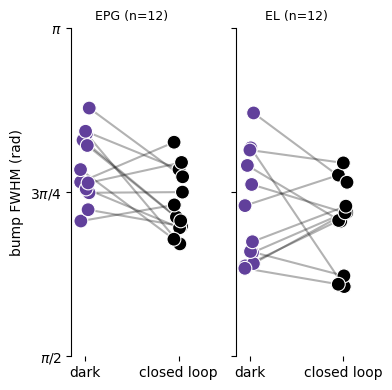

In [8]:
#check that this is implemented as desired, not sure I want bump size thresholding
fig, width_condition_tests = ec.plot_bump_width_by_condition(sess_manager, grouped_bump)
width_condition_tests

## Bump profiles during fast turns

{'clockwise': {'EPG': -6.50071031392697e-17, 'EL': -0.11624786741923666},
 'counter-clockwise': {'EPG': -8.096134766807324e-17,
  'EL': 0.08680894211256297}}

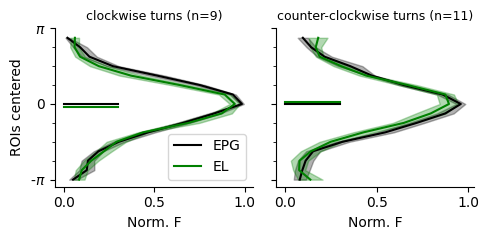

In [9]:
fig, turn_pva = ec.plot_turn_profiles(sess_manager)
turn_pva

## PV magnitude and PVA difference vs rotation speed

/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/figures/el_epg_coimaging/el_epg_coimaging_analysis.py:325: RuntimeWarning: Mean of empty slice
  return {col: stats_df.groupby(['fly_id', 'cl'])[col].apply(lambda x: np.nanmean(np.stack(x), axis=0)).reset_index()
/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/figures/el_epg_coimaging/el_epg_coimaging_analysis.py:325: RuntimeWarning: Mean of empty slice
  return {col: stats_df.groupby(['fly_id', 'cl'])[col].apply(lambda x: np.nanmean(np.stack(x), axis=0)).reset_index()
/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/figures/el_epg_coimaging/el_epg_coimaging_analysis.py:325: RuntimeWarning: Mean of empty slice
  return {col: stats_df.groupby(['fly_id', 'cl'])[col].apply(lambda x: np.nanmean(np.stack(x), axis=0)).reset_index()


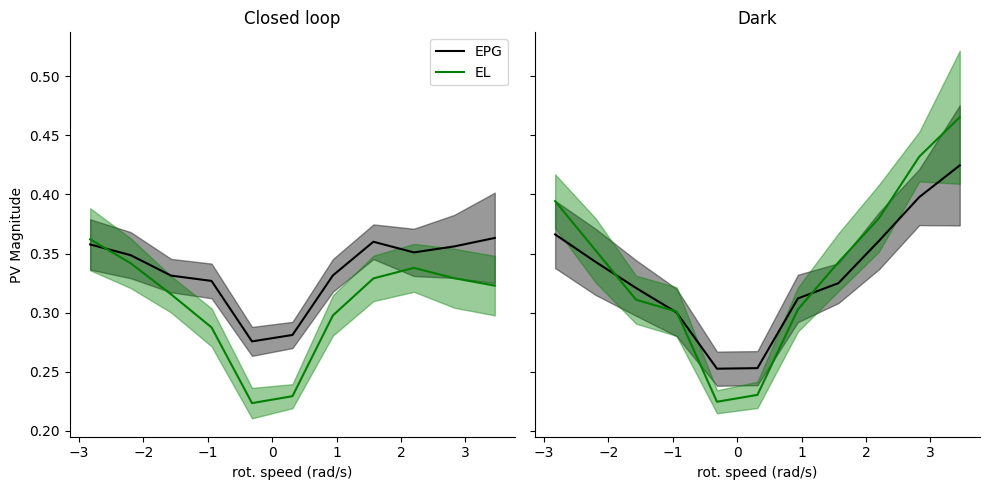

In [10]:
grouped = ec.compute_binned_stats(sess_manager)
fig = ec.plot_rho_vs_speed(sess_manager, grouped)

{'closed loop': {'r': 0.224223508953036, 'p': 0.010946628343887058},
 'dark': {'r': 0.32748696609167444, 'p': 7.371860657238539e-05}}

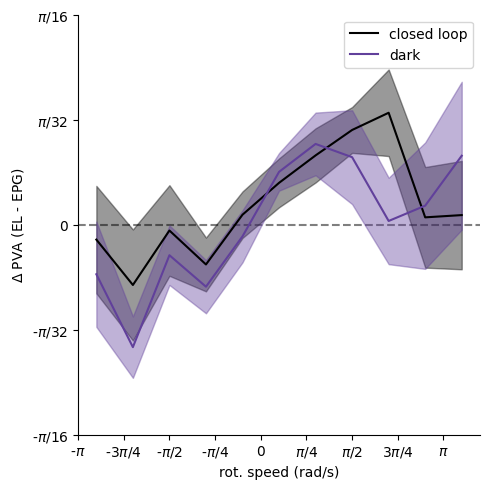

In [11]:
fig, spearman = ec.plot_pva_diff_vs_speed(sess_manager, grouped)
spearman

## PVA difference vs PV magnitude

/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/figures/el_epg_coimaging/el_epg_coimaging_analysis.py:363: RuntimeWarning: Mean of empty slice
  lambda x: np.nanmean(np.stack(x), axis=0)).reset_index()


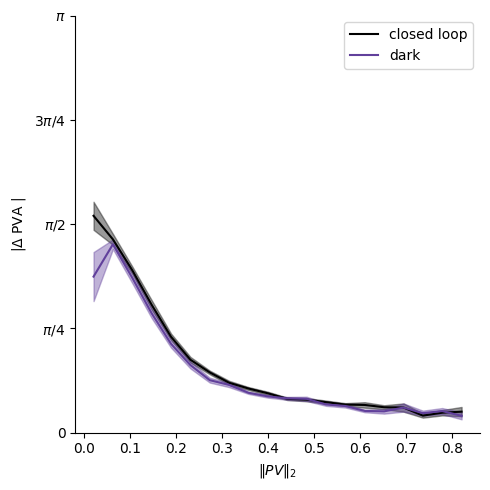

In [12]:
fig, grouped_pvd = ec.plot_pva_diff_vs_pv_magnitude(sess_manager)

## Figures of every session

In [31]:
n_sessions = ec.plot_session_figures(sess_manager)
print(f'{n_sessions} sessions')

34 sessions
